# **Arena**

## **Section 1: Setting directory and preparing the dataset**

In [1]:
%%capture
!pip install torchmetrics
!pip install pkbar
!pip install calflops
!pip install torchinfo
!pip install grad-cam

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Drive Directory**

In [3]:
import os
import zipfile
import json
import pandas as pd
import numpy as np
import random as rd
import shutil
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torchvision
from torchvision.transforms import v2, InterpolationMode
import timm
import calflops
from functools import partial

In [4]:
drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
dataset_name = 'MushroomA'
dataset_drive_dir = f'{drive_dir}/data/{dataset_name}'

model_name_path = 'resnext50_224_r1_v1' # เปลี่ยนเสมอ
model_name = 'ResNeXt50' # เปลี่ยนเสมอ
sigle_model_title = f'{model_name} on {dataset_name} Dataset'
ensemble_model_title = f'{model_name} Ensemble on {dataset_name} Dataset'
model_dir = os.path.join(drive_dir, f'modelWeights/{dataset_name}', f"{model_name_path}_{dataset_name}")
model_ensem_dir = f'{model_dir}/ensemble'
model_summary_dir = f'{model_dir}/summary'

os.makedirs(model_dir, exist_ok=True)
font_dir = f'{drive_dir}/assets/fonts'

os.chdir(f'{drive_dir}')
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


**Runtime Directory**

In [5]:
import src.reproducibility as reproducibility
import src.utils as utils
import src.datasets as datasets
import src.train as train
import src.test as test
import src.visualization as visualization
import src.gradCam as gradCam
import models.models as models

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')
def callbacks_fn(n_fold, fold_dir):
    checkpoint_path = f'{fold_dir}/{model_name_path}_{dataset_name}_best_weight.pth'
    return [utils.ModelCheckpoint(save_path=checkpoint_path, monitor=train.train_config['monitor'], mode=train.train_config['monitor_mode'])]

In [6]:
runtime_dir = '/content'
dataset_dir = f'{runtime_dir}/{dataset_name}'
os.makedirs(dataset_dir, exist_ok=True)

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on {device}.')
!python3 --version
!nvidia-smi

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Running on cuda.
Python 3.12.12
Thu Mar 19 12:28:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   45C    P8             14W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         | 

**Load data from G-Drive**

In [7]:
with zipfile.ZipFile(f'{dataset_drive_dir}/{dataset_name}_SPLIT.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

remain_classes = set(os.listdir(f'{dataset_dir}/remain'))
test_classes = set(os.listdir(f'{dataset_dir}/test'))
unique_classes = remain_classes.union(test_classes)
NUM_CLASSES = len(unique_classes)
print(f'Number of classes: {NUM_CLASSES}')
print(f'Dataset has been extracted to {dataset_dir}')

Number of classes: 9
Dataset has been extracted to /content/MushroomA


## **Section 2: Define model architecture**

In [8]:
model_fn = partial(
    models.build_baseline_model,
    model_name=model_name,
    num_classes=NUM_CLASSES,
    device=device,
    freeze_backbone=False
)
model = model_fn()

criterion = nn.CrossEntropyLoss()
optimizer_fn = lambda m : optim.AdamW(m.parameters(), lr=train.train_config['base_lr'], weight_decay=train.train_config['weight_decay'])
scheduler_fn = partial(optim.lr_scheduler.CosineAnnealingLR, T_max=train.train_config['max_epochs'])

model_config = models.get_transform_config(model)
summary(model, (1,) + model_config['input_size'], device=device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/100M [00:00<?, ?B/s]

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 9]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 256, 56, 56]          --
│    └─Bottleneck: 2-1                   [1, 256, 56, 56]          --
│    │    └─Conv2d: 3-1                  [1, 128, 56, 56]          8,192
│    │    └─BatchNorm2d: 3-2             [1, 128, 56, 56]          256
│    │    └─ReLU: 3-3                    [1, 128, 56, 56]          --
│    │    └─Conv2d: 3-4                  [1, 128, 56, 56]          4,608
│    │    └─BatchNorm2d: 3-5             [1, 128, 56, 56]          256
│    │    └─Identity: 3-6                [1, 128, 56, 56]          --
│  

## **Section 3: Preparing the dataset**

**Configuration for training**

In [9]:
img_size = model_config['img_size']
resize_size = int(img_size[0] / model_config['crop_pct'])
interp_mode = getattr(InterpolationMode, model_config['interpolation'].upper())
num_workers = min(4, os.cpu_count())

print(f'Image size: {img_size}')
print(f'Resize size: {resize_size}')
print(f'Interpolation mode: {interp_mode}')
print(f'Number of workers: {num_workers}')

reproducibility.global_seed(seed=train.train_config['seed'])
reproducibility.training_seed(seed=train.train_config['seed'])
g = reproducibility.get_generator(seed=train.train_config['seed'])

Image size: (224, 224)
Resize size: 256
Interpolation mode: InterpolationMode.BILINEAR
Number of workers: 4
Global Seed set to: 42
Training Seed set to: 42


In [10]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(img_size, scale=(0.08, 1.0), interpolation=interp_mode),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std']),
    v2.RandomErasing(p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
])

transform = v2.Compose([
    v2.Resize(resize_size, interpolation=interp_mode, max_size=None, antialias=True),
    v2.CenterCrop(img_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std'])
])

dataloader_kwargs = {
    'batch_size': train.train_config['batch_size'],
    'num_workers': num_workers,
    'worker_init_fn': reproducibility.seed_worker,
    'generator': g,
    'pin_memory': True
}

datasets = datasets.Datasets(
    dataset_dir=dataset_dir,
    train_transform=train_transform,
    transform=transform,
    dataloader_kwargs=dataloader_kwargs,
)

datasets.print_summary()
test_loader = datasets.get_test_loader()

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Class names       : ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']
Class to Index    : {'Agaricus': 0, 'Amanita': 1, 'Boletus': 2, 'Cortinarius': 3, 'Entoloma': 4, 'Hygrocybe': 5, 'Lactarius': 6, 'Russula': 7, 'Suillus': 8}
Index to Class    : {0: 'Agaricus', 1: 'Amanita', 2: 'Boletus', 3: 'Cortinarius', 4: 'Entoloma', 5: 'Hygrocybe', 6: 'Lactarius', 7: 'Russula', 8: 'Suillus'}
Total remain data : 5302
Total test data   : 1326
--------------------------------------------------


## **Section 4: Training the model**

In [11]:
trainer = train.KFoldTrainer(
    n_splits=train.train_config['n_folds'],
    shuffle=True,
    random_state=train.train_config['seed'],
    model_name=model_name_path,
    dataset_name=dataset_name,
    base_dir=model_dir,
    first_metric=train.train_config['first_metric'],
    first_metric_mode=train.train_config['first_metric_mode'],
    secondary_metric=train.train_config['secondary_metric'],
    secondary_metric_mode=train.train_config['secondary_metric_mode'],
    device=device,
    criterion=criterion,
    n_classes=NUM_CLASSES,
    task=train.train_config['task'],
    average=train.train_config['average'],
    max_grad_norm=0.0
)

[Logs] Setup directories at '/content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA' successfully.


In [12]:
fold_histories = trainer.fit_kfold(
    train_dataset=datasets.train_dataset,
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    model_fn=model_fn,
    optimizer_fn=optimizer_fn,
    epochs=train.train_config['max_epochs'],
    dataloader_kwargs=dataloader_kwargs,
    callbacks_fn=callbacks_fn,
    scheduler_fn=scheduler_fn
)

Starting Stratified 5-Fold Cross Validation

--------------------------------------------- FOLD 1/5 ---------------------------------------------
Epoch: 1/30
133/133 [==============================] - 31s 230ms/step - loss: 1.0918 - lr: 1.0000e-04 - accuracy: 0.6204 - f1: 0.5691 - precision: 0.6117 - recall: 0.5479
Epoch 1/30 | val_loss: 0.5054 - val_accuracy: 0.8247 - val_f1: 0.7975 - val_precision: 0.8303 - val_recall: 0.7893
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8247, saving model to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/fold_1/resnext50_224_r1_v1_MushroomA_best_weight.pth
Epoch: 2/30
133/133 [==============================] - 30s 223ms/step - loss: 0.6576 - lr: 9.9726e-05 - accuracy: 0.7769 - f1: 0.7564 - precision: 0.7681 - recall: 0.7471
Epoch 2/30 | val_loss: 0.3364 - val_accuracy: 0.8841 - val_f1: 0.8639 - val_precision: 0.8928 - val_recall: 0.8450
[Logs] Epoch: 2 val_accuracy improved from 0.8247 to 0.8841, s

Epoch: 1/30
133/133 [==============================] - 30s 226ms/step - loss: 1.0732 - lr: 1.0000e-04 - accuracy: 0.6264 - f1: 0.5715 - precision: 0.6232 - recall: 0.5492
Epoch 1/30 | val_loss: 0.4935 - val_accuracy: 0.8425 - val_f1: 0.8295 - val_precision: 0.8449 - val_recall: 0.8212
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8425, saving model to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/fold_4/resnext50_224_r1_v1_MushroomA_best_weight.pth
Epoch: 2/30
133/133 [==============================] - 30s 226ms/step - loss: 0.6464 - lr: 9.9726e-05 - accuracy: 0.7793 - f1: 0.7580 - precision: 0.7665 - recall: 0.7508
Epoch 2/30 | val_loss: 0.3572 - val_accuracy: 0.8745 - val_f1: 0.8433 - val_precision: 0.8684 - val_recall: 0.8279
[Logs] Epoch: 2 val_accuracy improved from 0.8425 to 0.8745, saving model to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/fold_4/resnext50_224_r1_v1_MushroomA_be

## **Section 5: Individual model performance**

In [13]:
y_true = test.get_true_label(test_loader, is_onehot=False)

### **Learning curve**

#### **Individual**

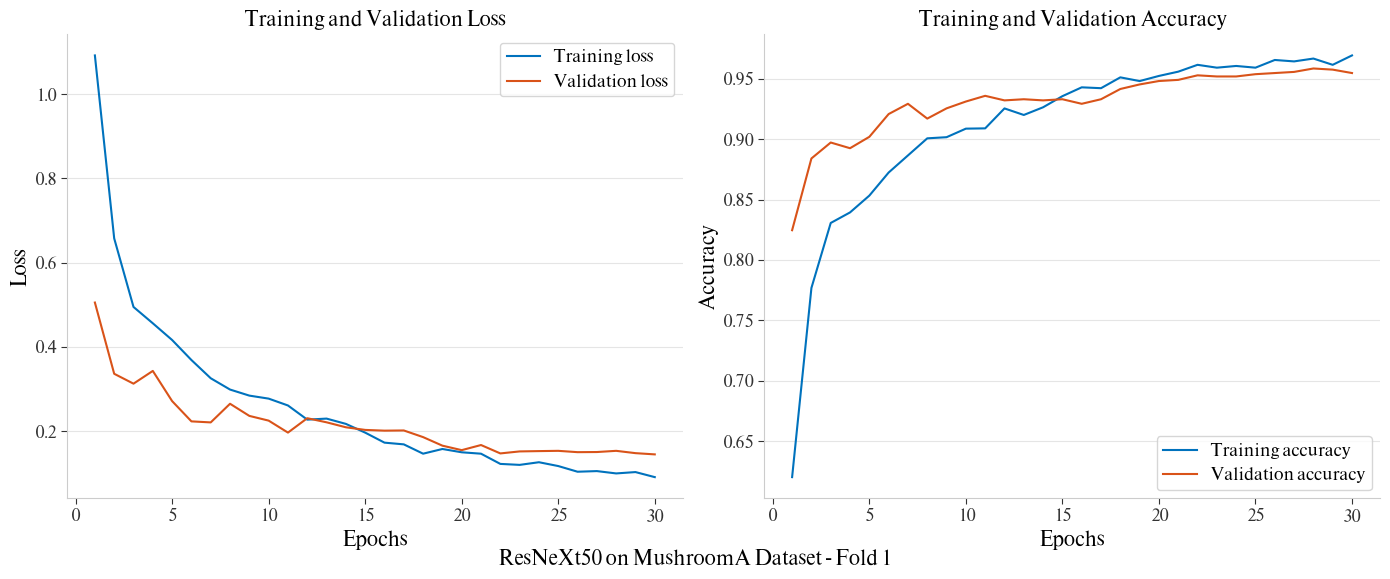

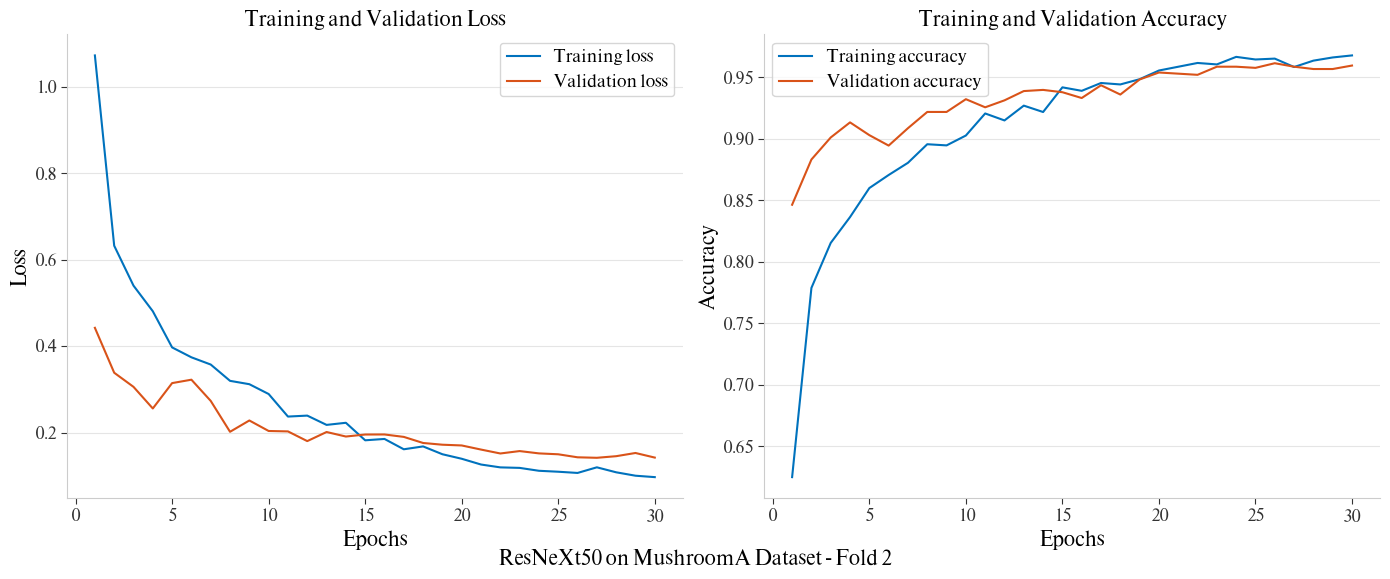

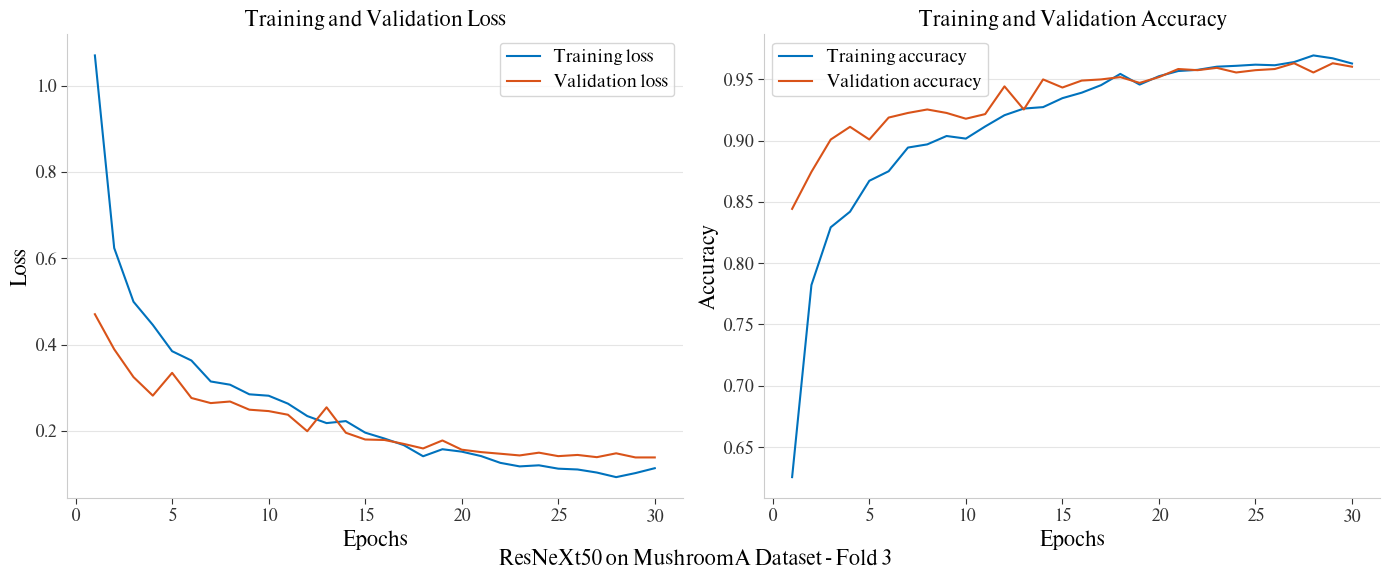

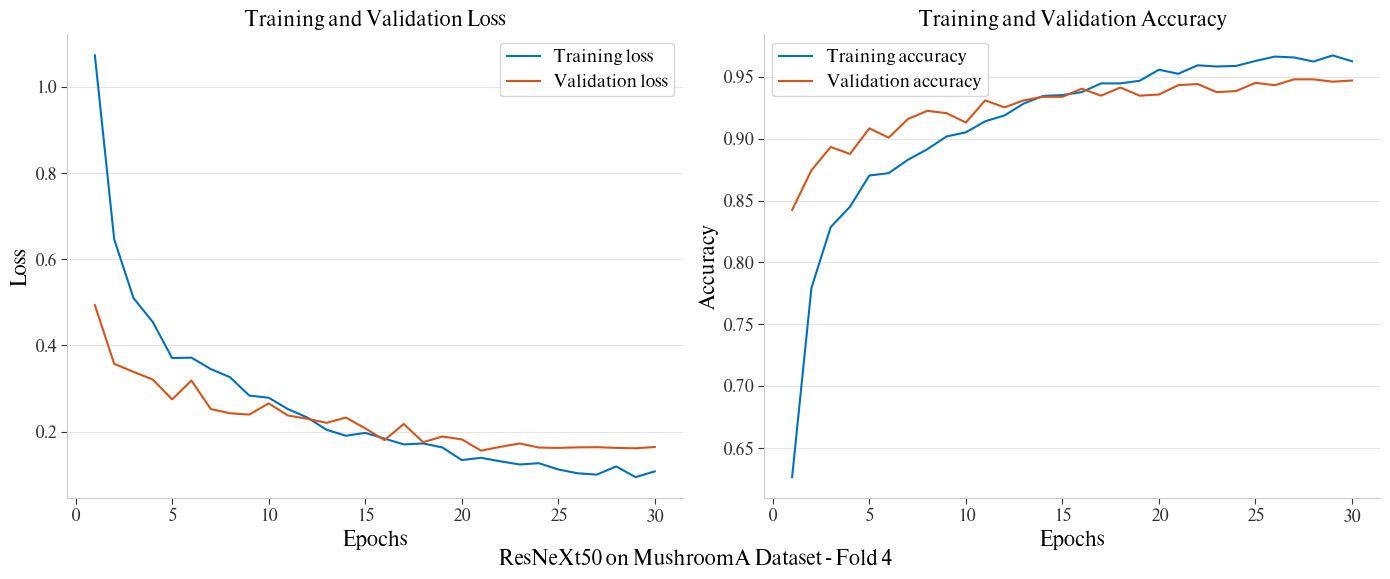

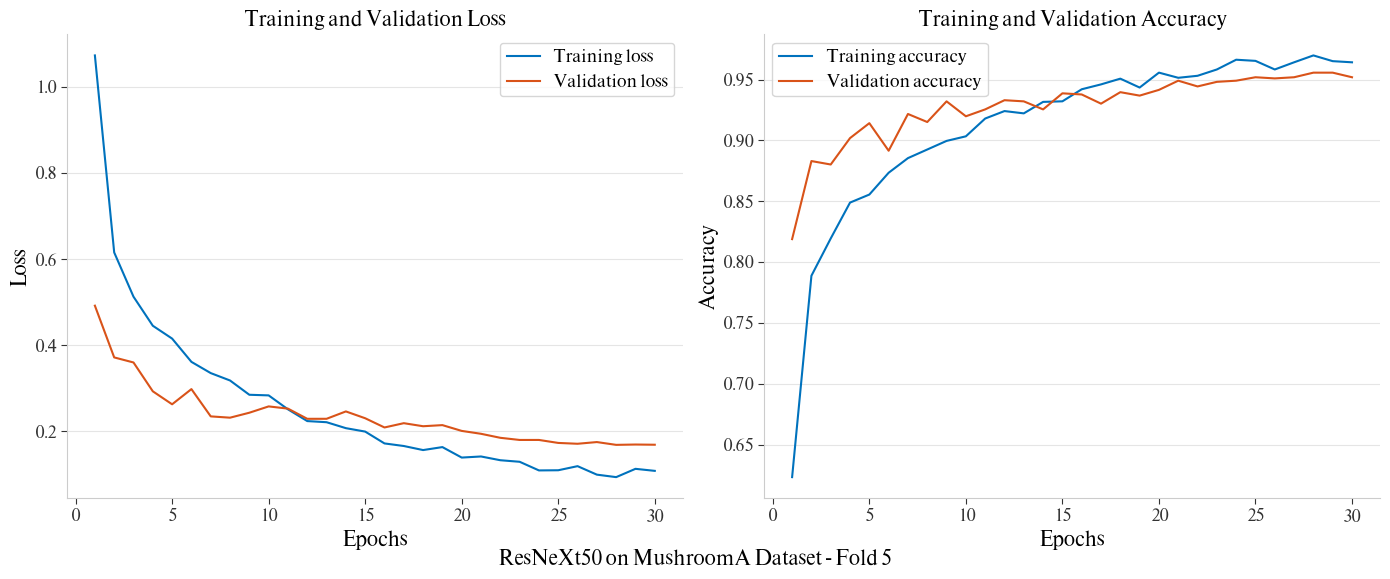

In [14]:
for fold_key, history in fold_histories.items():
    fold_num = fold_key.split('_')[1]
    fold_dir = f"{trainer.base_dir}/fold_{fold_num}"

    visualization.plot_lr_curve(
        history=history,
        figsize=(14, 6),
        fontsize=14,
        title=f"{sigle_model_title} - Fold {fold_num}",
        save_path=fold_dir
    )

    print('\n')

#### **Overall**

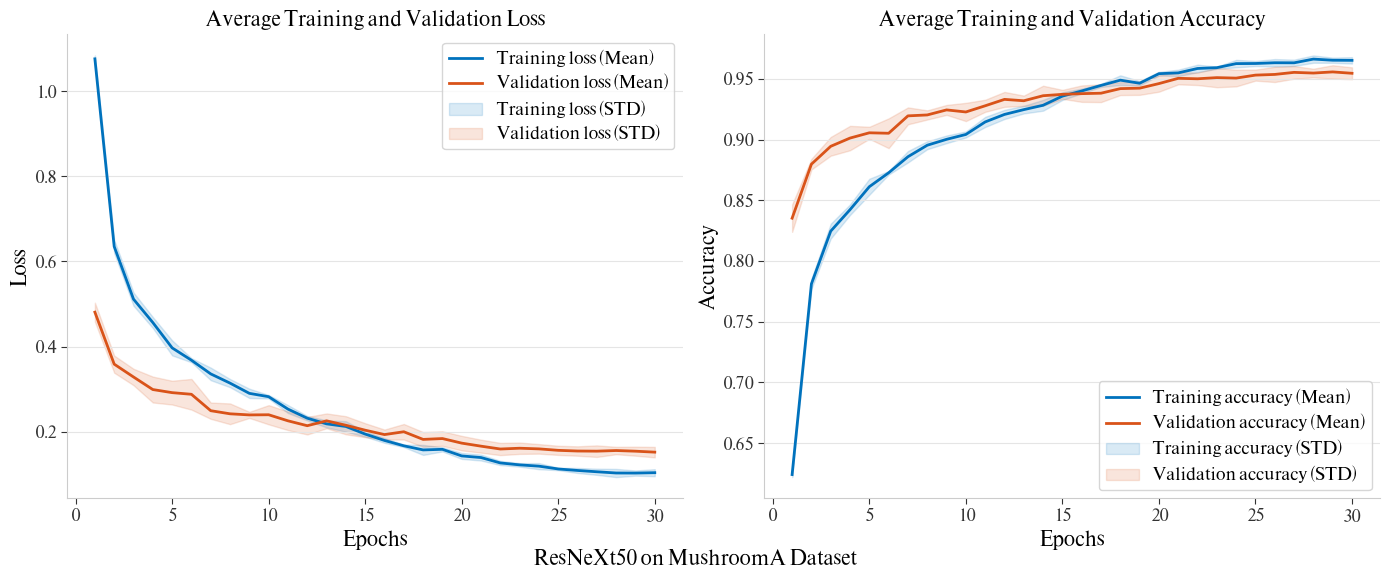

In [15]:
visualization.plot_cv_summary_curve(
    histories=list(fold_histories.values()),
    figsize=(14, 6),
    fontsize=14,
    title=sigle_model_title,
    save_path=model_ensem_dir
)

### **On validation set**

In [16]:
individual_validate_perf_df = trainer.evaluate_kfold(
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    dataloader_kwargs=dataloader_kwargs,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type']
)

Evaluating 5-Fold Models on their respective Validation Sets (BEST weights)

[*] Evaluating Fold 1/5 on its Validation Set...
34/34 [==============================] - 3s 90ms/step - loss: 0.1535 - accuracy: 0.9585 - f1: 0.9566 - precision: 0.9534 - recall: 0.9604
[*] Evaluating Fold 2/5 on its Validation Set...
34/34 [==============================] - 3s 88ms/step - loss: 0.1427 - accuracy: 0.9614 - f1: 0.9605 - precision: 0.9672 - recall: 0.9548
[*] Evaluating Fold 3/5 on its Validation Set...
34/34 [==============================] - 3s 88ms/step - loss: 0.1394 - accuracy: 0.9632 - f1: 0.9535 - precision: 0.9548 - recall: 0.9525
[*] Evaluating Fold 4/5 on its Validation Set...
34/34 [==============================] - 3s 89ms/step - loss: 0.1636 - accuracy: 0.9481 - f1: 0.9388 - precision: 0.9426 - recall: 0.9355
[*] Evaluating Fold 5/5 on its Validation Set...
34/34 [==============================] - 3s 89ms/step - loss: 0.1687 - accuracy: 0.9557 - f1: 0.9514 - precision: 0.9573 - rec

### **On test set**

In [17]:
ensemble_probs, timing_report = trainer.predict_kfold(
    dataloader=test_loader,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type'],
    timer_report_dict=True,
    verbose=1
)

Ensemble Prediction using 5-Fold Models (BEST weights)

[*] Running inference for Fold 1/5...
42/42 [==============================] - 4s 87ms/step

[Inference Report] Latency: 60.84 ms/batch | Throughput: 518.97 samples/sec
    -> Saved fold 1 timing report to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/fold_1/fold_1_infer_timing_report.csv
    -> Saved fold 1 predictions to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/fold_1/fold_1_test_probs_best_weight.csv
[*] Running inference for Fold 2/5...
42/42 [==============================] - 4s 84ms/step

[Inference Report] Latency: 60.47 ms/batch | Throughput: 522.12 samples/sec
    -> Saved fold 2 timing report to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/fold_2/fold_2_infer_timing_report.csv
    -> Saved fold 2 predictions to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext

In [18]:
individual_test_perf_df = test.evaluate_preds_kfold(
    base_dir=model_dir,
    n_splits=train.train_config['n_folds'],
    y_true=y_true,
    weight_type=train.train_config['weight_type'],
    task=train.train_config['task'],
    average=train.train_config['average'],
)

[*] Fold 1/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 2/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 3/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 4/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 5/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro

----------------------------------------------------------------------------------------------------
K-Fold Test Set Evaluation Results (Individual Models):
  Fold     loss  accuracy       f1  precision   recall
Fold 1 0.160051  0.953997 0.950615   0.952756 0.948708
Fold 2 0.180341  0.946456 0.942731   0.948199 0.938119
Fold 3 0.166440  0.948718 0.946625   0.950800 0.942742
Fold 4 0.184856  0.951735 0.946957   0.948883 0.945218
Fold 5 0.164929  0.953997 0.950130   0.953631 0.947106
  Mean 0.171323  0.950980 0.947412   0.950854 0.944379
   STD 0.010680  0.003330 0.003177   0.002359 0.004146
---------------------------

## **Section 6: Ensemble model performance**

### **On test set**

In [19]:
y_pred, metrics = test.evaluate_preds(
    y_true=y_true,
    y_probs=ensemble_probs,
    task=train.train_config['task'],
    average=train.train_config['average'],
    save_path=f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv'
)

[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/resnext50_224_r1_v1_MushroomA/ensemble/ensem_test_perf_best_weight.csv


### **Classification report**

In [20]:
report = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name)

report_dict = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(f'{model_ensem_dir}/ensem_classification_report.csv')

print('Classification Report on Ensemble')
print('=' * 100)
print(report)

Classification Report on Ensemble
              precision    recall  f1-score   support

    Agaricus     0.9701    0.9286    0.9489        70
     Amanita     0.9608    0.9800    0.9703       150
     Boletus     0.9859    0.9859    0.9859       213
 Cortinarius     0.9581    0.9581    0.9581       167
    Entoloma     0.9571    0.9178    0.9371        73
   Hygrocybe     1.0000    0.9841    0.9920        63
   Lactarius     0.9479    0.9700    0.9588       300
     Russula     0.9644    0.9518    0.9581       228
     Suillus     0.9516    0.9516    0.9516        62

    accuracy                         0.9638      1326
   macro avg     0.9662    0.9587    0.9623      1326
weighted avg     0.9639    0.9638    0.9638      1326



### **Correct predictions**

In [21]:
df_correct, df_incorrect = test.pred_records(
    y_true=y_true,
    y_pred=y_pred,
    y_probs=ensemble_probs,
    filepaths=[path for path, _ in test_loader.dataset.samples],
    idx_to_class=datasets.idx_to_class,
    save_dir=f'{model_ensem_dir}',
    prefix='ensem'
)

In [22]:
df_correct

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Agaricus/001_2jP9N_ipA...,Agaricus,Agaricus,0,0,0.844485
1,/content/MushroomA/test/Agaricus/016_qNYODERZE...,Agaricus,Agaricus,0,0,0.999987
2,/content/MushroomA/test/Agaricus/027_-CwuQDPSh...,Agaricus,Agaricus,0,0,0.967400
3,/content/MushroomA/test/Agaricus/028_-vDPakMKn...,Agaricus,Agaricus,0,0,0.999969
4,/content/MushroomA/test/Agaricus/042_qk77X1_g0...,Agaricus,Agaricus,0,0,0.999988
...,...,...,...,...,...,...
1273,/content/MushroomA/test/Suillus/297_XQdw8OtzxL...,Suillus,Suillus,8,8,0.965851
1274,/content/MushroomA/test/Suillus/308_KjxkhQlHYr...,Suillus,Suillus,8,8,0.813999
1275,/content/MushroomA/test/Suillus/311_MfqUejCCW5...,Suillus,Suillus,8,8,0.997673
1276,/content/MushroomA/test/Suillus/315_GvBoU4XjnT...,Suillus,Suillus,8,8,0.999733


### **Incorrect predictions**

In [23]:
df_incorrect

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Agaricus/119_D_g33HPgX...,Russula,Agaricus,7,0,0.450435
1,/content/MushroomA/test/Agaricus/202_b_NiIL4fe...,Amanita,Agaricus,1,0,0.609075
2,/content/MushroomA/test/Agaricus/320_ebYxJS43T...,Amanita,Agaricus,1,0,0.819665
3,/content/MushroomA/test/Agaricus/333_LwsnJQC9r...,Entoloma,Agaricus,4,0,0.770786
4,/content/MushroomA/test/Agaricus/354_VP-DWvLyI...,Amanita,Agaricus,1,0,0.993610
5,/content/MushroomA/test/Amanita/437_TI-chUFr6Z...,Entoloma,Amanita,4,1,0.472047
6,/content/MushroomA/test/Amanita/475_3-LU-M6jSU...,Russula,Amanita,7,1,0.996441
7,/content/MushroomA/test/Amanita/725_IybD3vqx0z...,Russula,Amanita,7,1,0.828536
8,/content/MushroomA/test/Boletus/0265_roqgqDagD...,Suillus,Boletus,8,2,0.617194
9,/content/MushroomA/test/Boletus/0654_S0ZETeWMB...,Suillus,Boletus,8,2,0.989150


### **Confusion matrix**

#### **without Normalize**

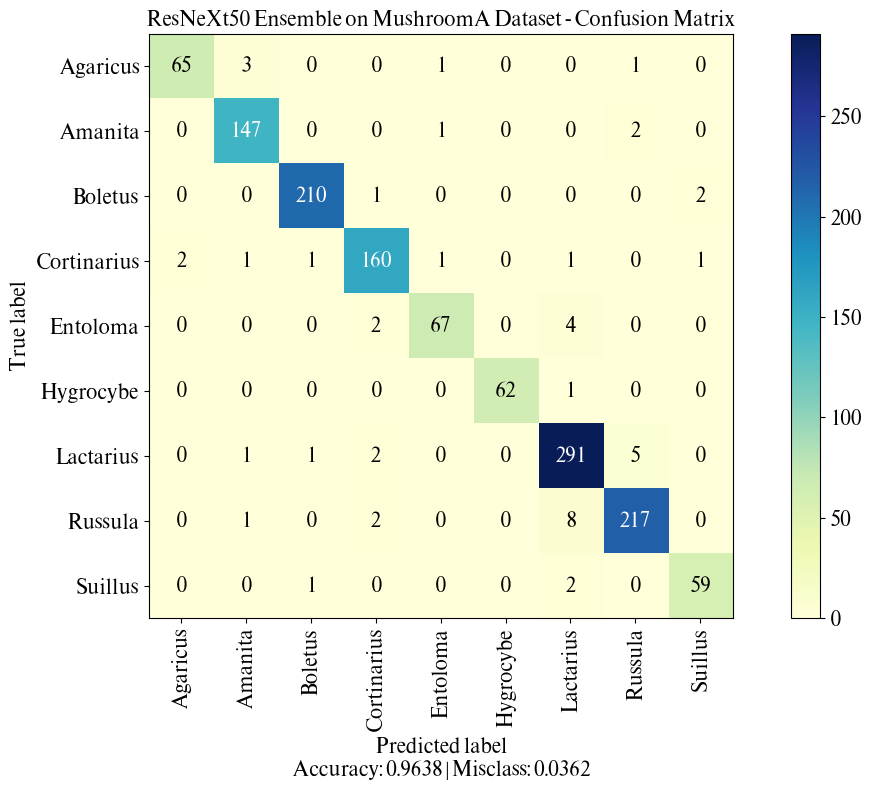

In [24]:
cm = confusion_matrix(y_true, y_pred)
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=False,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 8),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

#### **with Normalize**

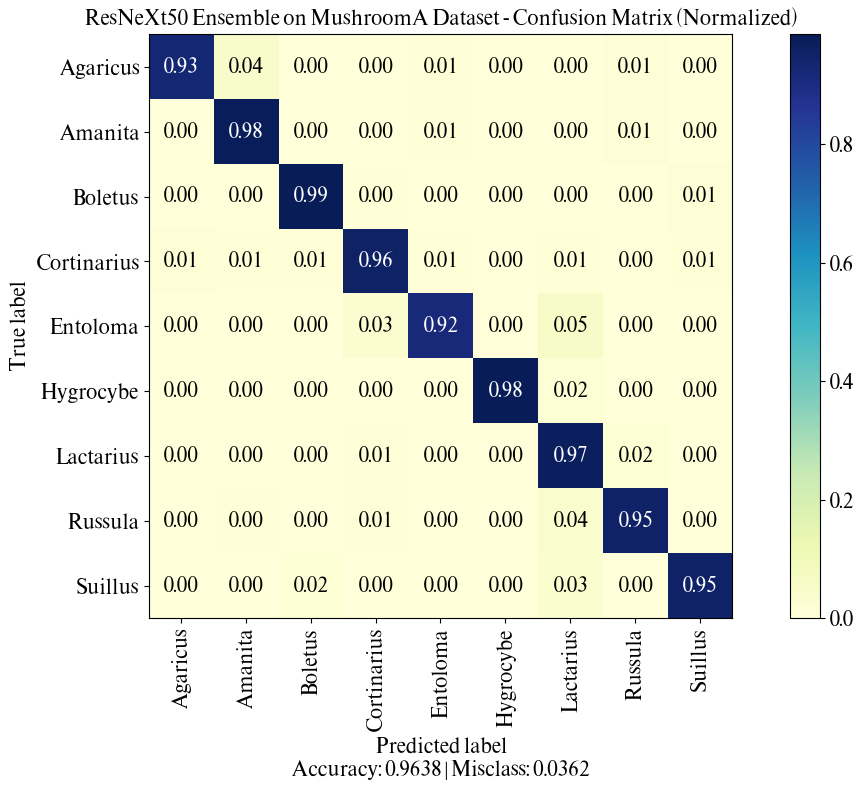

In [25]:
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=True,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 8),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

### **ROC-AUC curve**

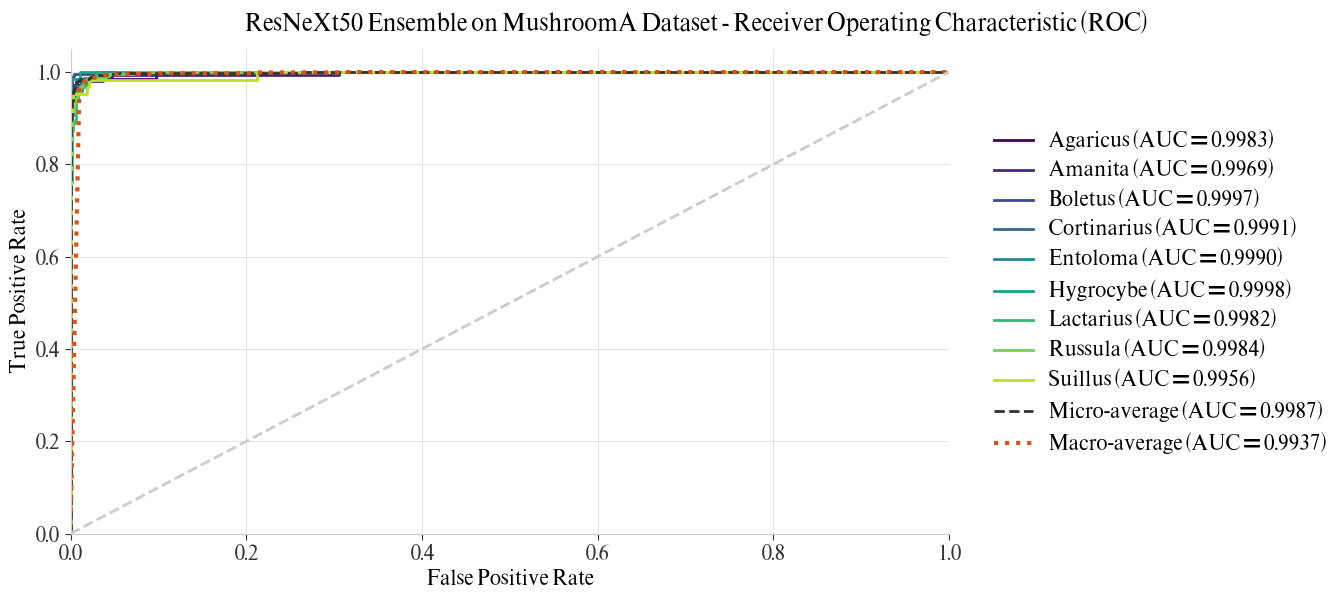

In [26]:
visualization.plot_roc_auc_curve(
    y_true=y_true,
    y_pred_probs=ensemble_probs,
    class_names=datasets.classes_name,
    task=train.train_config['task'],
    legend_ncol=1,
    figsize=(14, 6),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

## **Section 7: Grad-CAM**

In [27]:
best_model, best_fold_dir, best_fold_num = trainer.get_best_model_on_validate_set(model_fn=model_fn)
target_layers = [best_model.layer4[-1]]
print(target_layers)

[Logs] Retrieving Best Model from Fold 3
       Primary Metric: accuracy->0.9632 | Secondary: loss->0.1394 on Validation set.
[Bottleneck(
  (conv1): Conv2d(2048, 1024, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (conv2): Conv2d(1024, 1024, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
  (bn2): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (drop_block): Identity()
  (act2): ReLU(inplace=True)
  (aa): Identity()
  (conv3): Conv2d(1024, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act3): ReLU(inplace=True)
)]


In [28]:
unique_label = pd.read_csv(f'{dataset_drive_dir}/unique_label.csv')
#unique_label

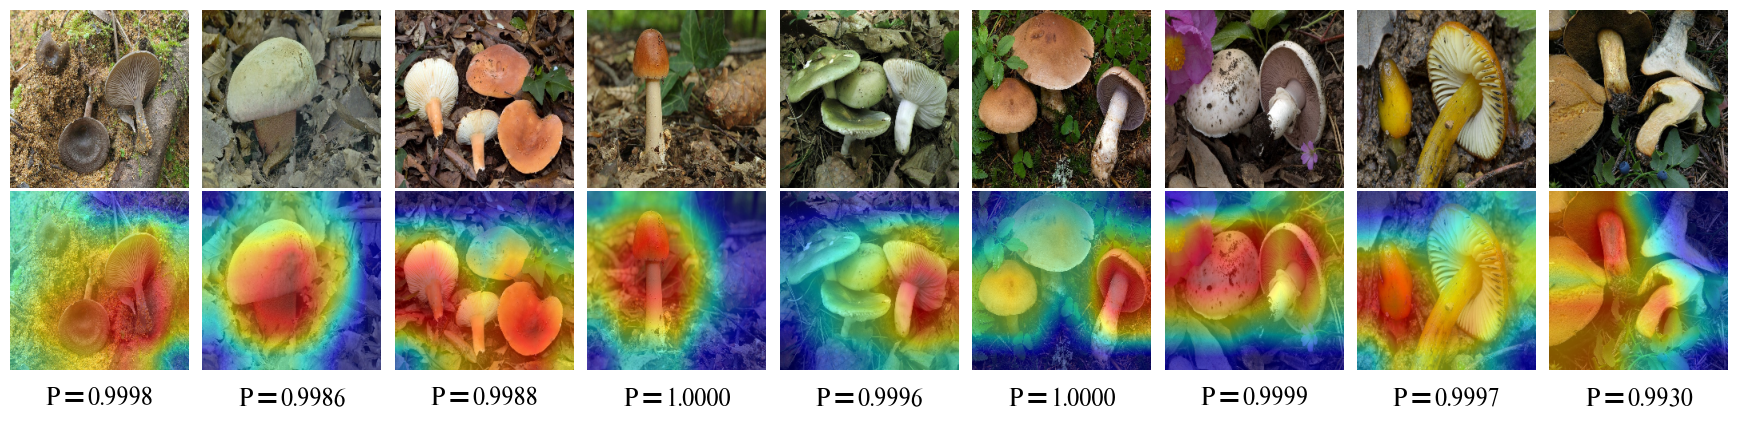

In [29]:
gradCam.plot_grad_cam(
    model=best_model,
    target_layers=target_layers,
    df=unique_label,
    filepaths_col='Filepaths',
    true_label_col='True_Label',
    true_idx='True_Index',
    device=device,
    transform=transform,
    task=train.train_config['task'],
    reshape_transform=None,
    img_size=model_config['img_size'],
    img_base_size=2,
    row_one_title=False,
    fontsize=16,
    save_path=model_ensem_dir
)

## **Section 8: Summary**

##### **Performace on Validation Set (N Folds)**

In [30]:
display(individual_validate_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.153543,0.958530,0.956636,0.953365,0.960432
Fold 2,0.142687,0.961357,0.960458,0.967215,0.954842
Fold 3,0.139395,0.963208,0.953537,0.954817,0.952474
Fold 4,0.163596,0.948113,0.938805,0.942551,0.935491
Fold 5,0.168659,0.955660,0.951450,0.957276,0.946135
Mean,0.153576,0.957374,0.952177,0.955045,0.949875
STD,0.012724,0.005915,0.008210,0.008832,0.009536


##### **Performace on Test Set (N Folds)**

In [31]:
display(individual_test_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.160051,0.953997,0.950615,0.952756,0.948708
Fold 2,0.180341,0.946456,0.942731,0.948199,0.938119
Fold 3,0.166440,0.948718,0.946625,0.950800,0.942742
Fold 4,0.184856,0.951735,0.946957,0.948883,0.945218
Fold 5,0.164929,0.953997,0.950130,0.953631,0.947106
Mean,0.171323,0.950980,0.947412,0.950854,0.944379
STD,0.010680,0.003330,0.003177,0.002359,0.004146


##### **Performace on Test Set (Ensemble)**

In [32]:
ensem_test_perf_df = pd.read_csv(f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv')
display(ensem_test_perf_df.style.hide(axis="index"))

loss,accuracy,f1,precision,recall
0.122646,0.963801,0.962305,0.966224,0.958653


#### **Model Info**

In [33]:
flops, macs, params = calflops.calculate_flops(
    model=best_model,
    input_shape=(1,) + model_config['input_size'],
    output_precision=4,
    print_results=False
)

flops_val = float(flops.split()[0])
if 'MFLOPS' in flops:
    flops_val /= 1000.0
flops = f'{flops_val:.4f}'

macs_val = float(macs.split()[0])
if 'MMACs' in macs:
    macs_val /= 1000.0
macs = f'{macs_val:.4f}'

params_val = float(params.split()[0])
if 'K' in params:
    params_val /= 1000.0
elif 'B' in params:
    params_val *= 1000.0
params = f'{params_val:.4f}'

model_summary_report = {
    'Batch Size': [train.train_config['batch_size']],
    'Image Size': [f'{img_size[0]}\u00D7{img_size[1]}'],
    'GFLOPs': [flops],
    'GMACs': [macs],
    'Params (M)': [params],
    'Latency (ms/img)': timing_report['avg_single_model_latency_sample'],
    'Latency (ms/batch)': timing_report['avg_single_model_latency_batch'],
    'Throughput (img/s)': timing_report['avg_single_model_throughput'],
}

model_summary_df = pd.DataFrame(model_summary_report)
model_summary_df.to_csv(f'{model_summary_dir}/model_summary.csv', index=False)
display(model_summary_df.style.hide(axis="index"))

Batch Size,Image Size,GFLOPs,GMACs,Params (M),Latency (ms/img),Latency (ms/batch),Throughput (img/s)
32,224×224,8.4995,4.2285,22.9983,1.919844,60.612229,520.876756
